In [1]:
import pandas as pd

# Анализ продаж в кафе

## Цель проекта

Определить, какие товары и условия продаж формируют наибольшую выручку, и выявить возможности для её увеличения.

## Этапы анализа

### 1. Очистка и подготовка данных

- Обработка пропущенных и некорректных значений
- Приведение типов данных
- Поиск и обработка дубликатов
- Проверка аномальных значений

### 2. Анализ продаж и выручки

- Определить товары с наибольшей выручкой
- Определить товары с наибольшим количеством проданных единиц
- Сравнить выручку и объём продаж между `In-store` и `Takeaway`
- Проанализировать структуру продаж по способам оплаты
- Проверить различия в продажах по дням недели
- Проанализировать динамику выручки и объёма продаж во времени

### 3. Выводы и рекомендации

- Определить основные источники выручки
- Выявить товары с потенциалом роста
- Сформулировать гипотезы по увеличению выручки и объёма продаж
- Определить, какие гипотезы требуют дополнительной проверки

In [2]:
sales = pd.read_csv("dirty_cafe_sales.csv")

In [3]:
sales.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [4]:
sales.columns = sales.columns.str.strip().str.lower().str.replace(" ", "_")
# Форматируем имена колон для удобной работы
sales.head()

,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [5]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   transaction_id    10000 non-null  str  
 1   item              9667 non-null   str  
 2   quantity          9862 non-null   str  
 3   price_per_unit    9821 non-null   str  
 4   total_spent       9827 non-null   str  
 5   payment_method    7421 non-null   str  
 6   location          6735 non-null   str  
 7   transaction_date  9841 non-null   str  
dtypes: str(8)
memory usage: 1.1 MB


In [6]:
sales.describe(include="all")

,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date
count,10000,9667,9862,9821,9827,7421,6735,9841
unique,10000,10,7,8,19,5,4,367
top,TXN_1961373,Juice,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,159


### Очистка и подготовка данных

In [7]:
sales.isna().sum()
# Количестово nan значений

transaction_id         0
item                 333
quantity             138
price_per_unit       179
total_spent          173
payment_method      2579
location            3265
transaction_date     159
dtype: int64

In [8]:
sales.duplicated().sum()
sales["transaction_id"].duplicated().sum()
# Дубликаты

np.int64(0)

In [9]:
sales["item"].value_counts()
sales["quantity"].value_counts()
sales["price_per_unit"].value_counts()
sales["total_spent"].value_counts()
sales["payment_method"].value_counts()
sales["location"].value_counts()
sales["transaction_date"].value_counts()

# В датасете обнаружены два значения UNKNOWN и ERROR, сменим их на nan во всем датасете
sales = sales.replace(["ERROR", "UNKNOWN"], pd.NA)

In [10]:
sales.isna().sum()
# Количестово nan значений

transaction_id         0
item                 969
quantity             479
price_per_unit       533
total_spent          502
payment_method      3178
location            3961
transaction_date     460
dtype: int64

In [11]:
# Cменим типы данных
sales["item"] = sales["item"].astype("category")
sales["quantity"] = sales["quantity"].astype("Int16")
sales["price_per_unit"] = sales["price_per_unit"].astype("Float32")
sales["total_spent"] = sales["total_spent"].astype("Float32")
sales["payment_method"] = sales["payment_method"].astype("category")
sales["location"] = sales["location"].astype("category")
sales["transaction_date"] = pd.to_datetime(sales["transaction_date"], errors="coerce")
sales.info()
sales.head()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    10000 non-null  str           
 1   item              9031 non-null   category      
 2   quantity          9521 non-null   Int16         
 3   price_per_unit    9467 non-null   Float32       
 4   total_spent       9498 non-null   Float32       
 5   payment_method    6822 non-null   category      
 6   location          6039 non-null   category      
 7   transaction_date  9540 non-null   datetime64[us]
dtypes: Float32(2), Int16(1), category(3), datetime64[us](1), str(1)
memory usage: 420.2 KB


,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,<NA>,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [12]:
# Зная наименования товара определим стоимость за единцу
sales.loc[
    sales["price_per_unit"].isna() & (sales["item"] == "Salad"), "price_per_unit"
] = 5

sales.loc[
    sales["price_per_unit"].isna() & sales["item"].isin(["Smoothie", "Sandwich"]),
    "price_per_unit",
] = 4

sales.loc[
    sales["price_per_unit"].isna() & sales["item"].isin(["Cake", "Juice"]),
    "price_per_unit",
] = 3

sales.loc[
    sales["price_per_unit"].isna() & (sales["item"] == "Coffee"), "price_per_unit"
] = 2

sales.loc[
    sales["price_per_unit"].isna() & (sales["item"] == "Tea"), "price_per_unit"
] = 1.5

sales.loc[
    sales["price_per_unit"].isna() & (sales["item"] == "Cookie"), "price_per_unit"
] = 1

In [13]:
menu = (
    sales[["item", "price_per_unit"]]
    .drop_duplicates()
    .sort_values("price_per_unit", ascending=False)
)

In [14]:
# Заполним значения nan для трех колон через неравенство total_spent = price_per_unit * quantity
sales.loc[
    sales["quantity"].isna()
    & sales["total_spent"].notna()
    & sales["price_per_unit"].notna(),
    "quantity",
] = sales["total_spent"] / sales["price_per_unit"]

sales.loc[
    sales["total_spent"].isna()
    & sales["quantity"].notna()
    & sales["price_per_unit"].notna(),
    "total_spent",
] = sales["quantity"] * sales["price_per_unit"]
sales.loc[
    sales["price_per_unit"].isna()
    & sales["quantity"].notna()
    & sales["total_spent"].notna(),
    "price_per_unit",
] = sales["total_spent"] / sales["quantity"]

In [15]:
menu

,item,price_per_unit
3,Salad,5.0
52,NaN,5.0
5,Smoothie,4.0
7,Sandwich,4.0
165,NaN,4.0
1,Cake,3.0
6,NaN,3.0
17,Juice,3.0
0,Coffee,2.0
30,NaN,2.0


In [16]:
# Теперь когда рассчитаны значения для price_per_unit вместо nan определяем значения для item
# Для универсальной цены
sales.loc[sales["item"].isna() & (sales["price_per_unit"] == 5), "item"] = "Salad"

sales.loc[sales["item"].isna() & (sales["price_per_unit"] == 2), "item"] = "Coffee"

sales.loc[sales["item"].isna() & (sales["price_per_unit"] == 1.5), "item"] = "Tea"

sales.loc[sales["item"].isna() & (sales["price_per_unit"] == 1), "item"] = "Cookie"

In [17]:
sales.info()
sales.isna().sum()
# Количестово nan значений

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    10000 non-null  str           
 1   item              9520 non-null   category      
 2   quantity          9977 non-null   Int16         
 3   price_per_unit    9994 non-null   Float32       
 4   total_spent       9977 non-null   Float32       
 5   payment_method    6822 non-null   category      
 6   location          6039 non-null   category      
 7   transaction_date  9540 non-null   datetime64[us]
dtypes: Float32(2), Int16(1), category(3), datetime64[us](1), str(1)
memory usage: 420.5 KB


transaction_id         0
item                 480
quantity              23
price_per_unit         6
total_spent           23
payment_method      3178
location            3961
transaction_date     460
dtype: int64

In [46]:
# Проверка: есть ли строки, где среди этих трёх числовых колонок известны два значения.
cols = ["quantity", "price_per_unit", "total_spent"]
sales.loc[sales[cols].notna().sum(axis=1) == 2, cols]

,quantity,price_per_unit,total_spent


In [45]:
# Проверка: совпадает ли арифметика — quantity × price_per_unit = total_spent.
sales.loc[sales["quantity"] * sales["price_per_unit"] != sales["total_spent"], cols]

,quantity,price_per_unit,total_spent


In [20]:
sales["payment_method"].value_counts(dropna=False)
sales["location"].value_counts(dropna=False)
pd.crosstab(sales["location"], sales["payment_method"], dropna=False)

payment_method,Cash,Credit Card,Digital Wallet
location,,,
NaN,892,923,852
In-store,702,681,695
Takeaway,664,669,744


### Анализ продаж и выручки

In [21]:
sales.head()

,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,4.0,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [22]:
# Товары с наибольшей вуручкой
sales.groupby("item")["total_spent"].sum().sort_values(ascending=False)

item
Salad       19095.0
Sandwich    13716.0
Smoothie    13344.0
Juice       10515.0
Cake        10404.0
Coffee       7808.0
Tea          5475.0
Cookie       3598.0
Name: total_spent, dtype: Float32

In [23]:
sales.loc[sales["item"].isna() & sales["price_per_unit"].isin([3, 4])].groupby(
    "price_per_unit"
)["total_spent"].sum()

# У нас остались транзакции без позиций так как цена была не уникальная (для 3 и 4 дол)
# Рассчитываем выручку отдельно для них

price_per_unit
3.0    2271.0
4.0    2816.0
Name: total_spent, dtype: Float32

In [24]:
# Распредиления позиций с ценой 3 и 4 по количеству транзакций
sales.loc[sales["item"].isin(["Cake", "Juice"]), "item"].value_counts(
    normalize=True
).to_frame("share").style.format("{:.1%}")

sales.loc[sales["item"].isin(["Smoothie", "Sandwich"]), "item"].value_counts(
    normalize=True
).to_frame("share").style.format("{:.1%}")

,share
item,
Sandwich,50.8%
Smoothie,49.2%
Cake,0.0%
Coffee,0.0%
Cookie,0.0%
Juice,0.0%
Salad,0.0%
Tea,0.0%


In [25]:
# Распредиления позиций с ценой 3 и 4 по количеству единиц
cake_juice_quantity_share = (
    sales.loc[sales["item"].isin(["Cake", "Juice"])].groupby("item")["quantity"].sum()
)
cake_juice_quantity_share / cake_juice_quantity_share.sum() * 100


sandwich_smoothie_quantity_share = (
    sales.loc[sales["item"].isin(["Sandwich", "Smoothie"])]
    .groupby("item")["quantity"]
    .sum()
)
sandwich_smoothie_quantity_share / sandwich_smoothie_quantity_share.sum() * 100

item
Sandwich    50.687361
Smoothie    49.312639
Name: quantity, dtype: Float64

Для товаров с общей ценой 3 и 4 доллара часть транзакций не удалось однозначно отнести к конкретному item. Распределение известных позиций с той же ценой по количеству транзакций и по quantity было близко к 50/50, неопределённую выручку распределим поровну между соответствующими товарами.

In [26]:
unknown_3 = sales.loc[
    sales["item"].isna() & (sales["price_per_unit"] == 3),
    "total_spent",
].sum()

unknown_4 = sales.loc[
    sales["item"].isna() & (sales["price_per_unit"] == 4),
    "total_spent",
].sum()

item_revenue = sales.groupby("item")["total_spent"].sum()

item_revenue["Cake"] += unknown_3 / 2
item_revenue["Juice"] += unknown_3 / 2

item_revenue["Sandwich"] += unknown_4 / 2
item_revenue["Smoothie"] += unknown_4 / 2

item_revenue.sort_values(ascending=False)

item
Salad       19095.0
Sandwich    15124.0
Smoothie    14752.0
Juice       11650.5
Cake        11539.5
Coffee       7808.0
Tea          5475.0
Cookie       3598.0
Name: total_spent, dtype: Float32

Text(0, 0.5, '')

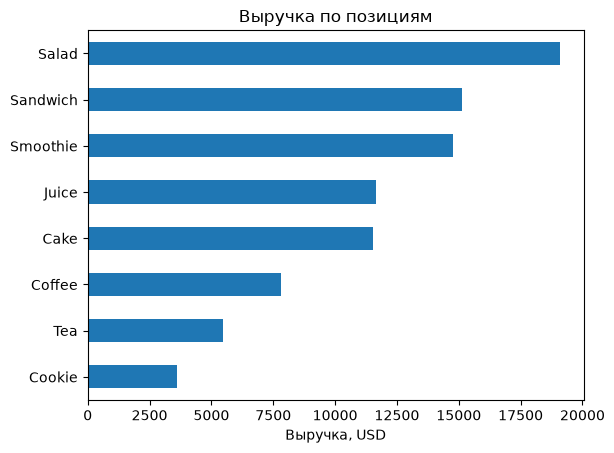

In [27]:
value_plot = item_revenue.sort_values().plot(kind="barh", title="Выручка по позициям")
value_plot.set_xlabel("Выручка, USD")
value_plot.set_ylabel("")

Text(0, 0.5, '')

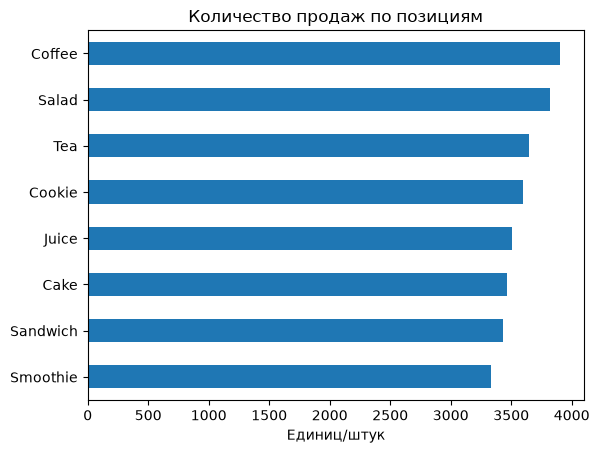

In [28]:
# Посмотрим по количеству  quantity
sales.groupby("item")["quantity"].sum().sort_values(ascending=False)
quantity_plot = (
    sales.groupby("item")["quantity"]
    .sum()
    .sort_values()
    .plot(kind="barh", title="Количество продаж по позициям")
)
quantity_plot.set_xlabel("Единиц/штук")
quantity_plot.set_ylabel("")

In [30]:
sales["item"].value_counts()

item
Coffee      1291
Salad       1272
Cookie      1213
Tea         1207
Juice       1171
Cake        1139
Sandwich    1131
Smoothie    1096
Name: count, dtype: int64

Text(0, 0.5, '')

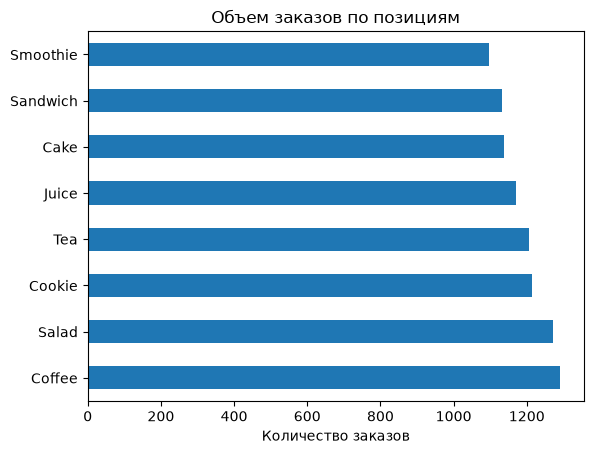

In [31]:
orders_count = (
    sales["item"].value_counts().plot(kind="barh", title="Объем заказов по позициям")
)
orders_count.set_xlabel("Количество заказов")
orders_count.set_ylabel("")

In [32]:
sales["item"].value_counts().describe()

count       8.000000
mean     1190.000000
std        68.683539
min      1096.000000
25%      1137.000000
50%      1189.000000
75%      1227.750000
max      1291.000000
Name: count, dtype: float64

In [33]:
item_revenue_share = item_revenue / item_revenue.sum() * 100

item_revenue_share.sort_values(ascending=False).to_frame("revenue_share").style.format(
    {"revenue_share": "{:.1f}%"}
)

,revenue_share
item,
Salad,21.4%
Sandwich,17.0%
Smoothie,16.6%
Juice,13.1%
Cake,13.0%
Coffee,8.8%
Tea,6.1%
Cookie,4.0%


Количество транзакций и количество проданных единиц распределены между позициями меню относительно равномерно. Выручка значительно различается: наибольшую выручку формируют более дорогие позиции Salad - 21.4%,
Sandwich - 17.0%, Smoothie - 16.6%. Различия в выручке в большей степени связаны с ценой позиции.

In [34]:
location_stats = sales.groupby("location").agg(
    revenue=("total_spent", "sum"),
    quantity=("quantity", "sum"),
    transactions=("item", "size"),
)
location_share = location_stats.div(location_stats.sum())
location_share.style.format("{:.1%}")

,revenue,quantity,transactions
location,,,
In-store,50.6%,50.0%,50.0%
Takeaway,49.4%,50.0%,50.0%


In [35]:
sales.head()

,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,4.0,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [36]:
method_stats = sales.groupby("payment_method").agg(
    revenue=("total_spent", "sum"),
    quantity=("quantity", "sum"),
    transactions=("item", "size"),
)
method_stats_share = method_stats / (method_stats.sum())
method_stats_share.style.format("{:.1%}")
# Продажи равномерно распределены между способами оплаты

,revenue,quantity,transactions
payment_method,,,
Cash,33.3%,33.2%,33.1%
Credit Card,33.4%,33.2%,33.3%
Digital Wallet,33.3%,33.6%,33.6%


<Axes: title={'center': 'Выручка по дням недели'}, xlabel='USD'>

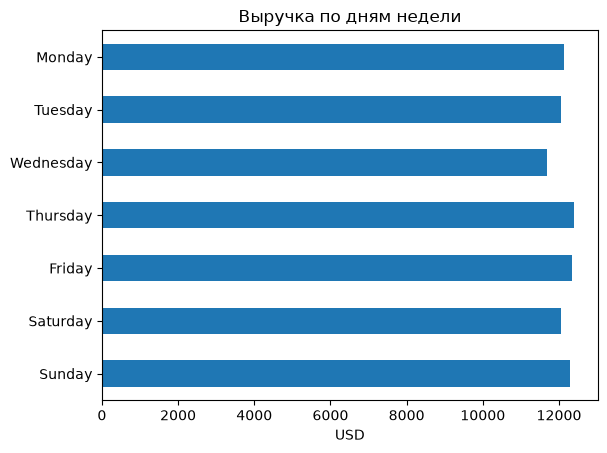

In [37]:
sales["date_week"] = sales["transaction_date"].dt.day_name()
days_stats = sales.groupby("date_week").agg(
    revenue=("total_spent", "sum"),
    quantity=("quantity", "sum"),
    transactions=("item", "size"),
)
days_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

days_stats = days_stats.reindex(days_order)
days_stats["revenue"][::-1].plot(
    kind="barh", title="Выручка по дням недели", ylabel="", xlabel="USD"
)

In [38]:
sales["month"] = sales["transaction_date"].dt.month_name()
month_stats = sales.groupby("month").agg(
    revenue=("total_spent", "sum"),
    quantity=("quantity", "sum"),
    transactions=("item", "size"),
)
month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December",
]
month_stats = month_stats.reindex(month_order)
month_stats

,revenue,quantity,transactions
month,,,
January,7254.0,2448,818
February,6644.0,2257,727
March,7216.0,2470,827
April,7179.0,2373,774
May,6957.5,2332,777
June,7353.0,2461,818
July,6877.5,2337,791
August,7112.5,2410,803
September,6871.0,2358,788


<Axes: title={'center': 'Выручка по месяцам'}, xlabel='month'>

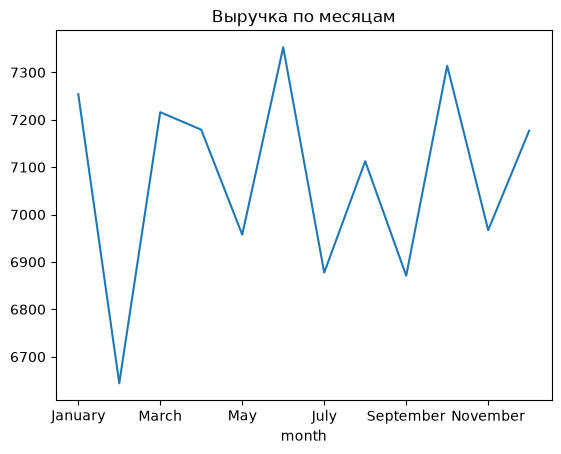

In [39]:
month_stats["revenue"].plot(title="Выручка по месяцам")

In [40]:
sales.groupby("month")["transaction_date"].nunique()

month
April        30
August       31
December     31
February     28
January      31
July         31
June         30
March        31
May          31
November     30
October      31
September    30
Name: transaction_date, dtype: int64

# Выводы

### Количество транзакций

Количество транзакций по позициям меню распределено относительно равномерно, без существенного разрыва между наиболее и наименее продаваемыми позициями.

- Максимум: **Coffee — 1291 транзакция**
- Минимум: **Smoothie — 1096 транзакций**
- Среднее: **≈ 1190 транзакций**

### Количество проданных единиц

Количество проданных единиц также распределено относительно равномерно между позициями меню.

- Максимум: **Coffee — 3904 единицы**
- Минимум: **Smoothie — 3336 единиц**
- Среднее: **≈ 3589 единиц**

Таким образом, существенной разницы в популярности товаров по количеству продаж не наблюдается.

### Выручка

В отличие от количества продаж, выручка между позициями различается заметнее. Наибольшую долю общей выручки формируют:

1. **Salad — 21,4% (19 095 USD)**
2. **Sandwich — 17,0% (15 124 USD)**
3. **Smoothie — 16,6% (14 752 USD)**

При этом количество проданных единиц по позициям отличается относительно незначительно. Следовательно, различия в выручке в большей степени связаны с **ценой товаров**, а не с существенной разницей в объёме продаж.

Распределение продаж по способам оплаты и между форматами In-store и Takeaway существенно не отличается. Также не выявлено выраженных различий в продажах по дням недели и месяцам. Заметной сезонности или временных закономерностей в рамках анализируемого периода не обнаружено.

# Рекомендации

- Сосредоточить дальнейший анализ на товарах, которые формируют наибольшую выручку, и изучить их ценовые и качественные характеристики.
- Рассмотреть возможность развития ассортимента на основе наиболее прибыльных ценовых категорий.